# TITLE PLACE HOLDER

SOME TEXT HERE

---
## Pre processing of the datasets

SOME TEXT HERE

In [ ]:
import pandas as pd;
import numpy as np;

data = pd.read_excel("Data/meta Niloofar 8.10.404.final.xlsx");
data = data.drop(columns=['Column1', 'N0.']);

# Forward fill these categorical features
data["Author"] = data["Author"].ffill();
data["Cancer"] = data["Cancer"].ffill();
data["Cell Line"] = data["Cell Line"].ffill();

# 1. Remove all whitespace
data["Unit"] = data["Unit"].str.replace(r"\s+", "", regex=True);
data["Time"] = data["Time"].str.replace(r"\s+", "", regex=True);

# 2. Normalize unicode µ signs to standard 'µ'
data["Unit"] = data["Unit"].str.replace('μ', 'µ')

# 3. Lowercase for consistency
data["Unit"] = data["Unit"].str.lower();
data["Time"] = data["Time"].str.lower();


print(data["Unit"].unique())
print(data["Unit"].value_counts())

# Molecular weight of Osthole.
MW = 244.28;

# The new data (Osthole data) needs unit transformation.
def to_uM(row):
    if row["Unit"].strip() == "mg/ml":
        return row["Dose"] * 1e6 / MW;

    elif row["Unit"].strip() == "nm":
        return row["Dose"] * 1e-3;

    elif row["Unit"].strip() == "µg/ml":
        return row['Dose'] * 1e3 / MW;

    else:
        return row["Dose"];

data["Dose"] = data.apply(to_uM, axis=1)
data["Dose"] = data["Dose"].round(2);

data["Unit"] = "µM"
data["Coumarin"] = "Osthole"
col = data.pop("Coumarin");
data.insert(3, 'Coumarin', col);
col = data.pop("Time");
data.insert(5, 'Time', col);

data.to_csv("Data/cleanedData.csv", index=False);

# Now we shall concatenate this data to the old one.

# Load the old dataset

oldData = pd.read_csv("Data/oldData.csv");

# print(oldData.columns);

# Just some re ordering and renaming of the feaatures to concat to the new osthole data easily
oldData = oldData[['Seo', 'Cancer Type', 'Cell Line', 'Coumarin Type', 'Coumarin Dose', 'Time', 'Viability']];
oldData.columns = ['Author', 'Cancer', 'Cell Line', 'Coumarin', 'Dose', 'Time', "Viability"];
newData = data[['Author', 'Cancer', 'Cell Line', 'Coumarin', 'Dose', 'Time', "Viability"]]

# Make the time feature numerical
newData['Time'] = newData['Time'].str.replace(r'\D', '', regex=True).astype(int);

# Concat the datas toghether
finalDataset = pd.concat([oldData, newData]);

finalDataset['Cancer'] = finalDataset['Cancer'].str.strip().str.lower().str.replace('\n', ' ', regex=False);

mapping = {
    # Prostate
    'prostate': 'prostate',
    'prostate cancer': 'prostate',

    # Breast
    'breast': 'breast',

    # Lung
    'lung': 'lung',
    'lung cancer': 'lung',
    'lung adenocarcinoma': 'lung',

    # Colon / Colorectal
    'colon': 'colon',
    'colorectal cancer': 'colon',
    'colon adenocarcinoma': 'colon',

    # Liver
    'liver': 'liver',
    'hepatocellular carcinoma': 'liver',

    # Cholangiocarcinoma
    'cholangiocarcinoma': 'cholangiocarcinoma',
    'intrahepatic cholangiocarcinoma': 'cholangiocarcinoma',

    # Cervical
    'cervical': 'cervical',
    'cervix': 'cervical',
    'cervical carcinoma': 'cervical',

    # Ovarian
    'ovarian': 'ovarian',
    'ovarian carcinoma': 'ovarian',
    'ovarian endometrioid adenocarcinoma': 'ovarian',

    # Endometrial / Uterine
    'uterine': 'endometrial',
    'endometrial': 'endometrial',

    # Renal
    'renal': 'renal',
    'renal cell carcinoma': 'renal',

    # Bone
    'bone': 'bone',
    'osteosarcoma': 'bone',

    # Skin
    'skin': 'skin',
    'melanoma': 'melanoma',

    # Brain tumors
    'glioma': 'glioma',
    'glioblastoma': 'glioma',
    'oligodendroglioma': 'glioma',
    'medulloblastoma': 'medulloblastoma',

    # Other organs
    'gastric': 'gastric',
    'pancreatic': 'pancreatic',
    'oral': 'oral',
    'salivary gland': 'salivary gland',
    'bladder': 'bladder',
    'nasopharyngeal': 'nasopharyngeal',
    'esophageal squamous cell carcinoma': 'esophageal',
    'gallbladder cancer': 'gallbladder',
    'leukemia/lymphoma': 'leukemia:lymphoma'
}

finalDataset['Cancer'] = finalDataset['Cancer'].replace(mapping);
finalDataset.columns = finalDataset.columns.str.replace(" ", "", regex=False);
finalDataset.columns = finalDataset.columns.str.strip();


print(finalDataset['Cancer'].unique())
print(finalDataset['Cancer'].value_counts())

finalDataset.to_csv("Data/Final_Data.csv", index = False);

print(finalDataset["Coumarin"].value_counts())

---
## Feature Engineering

The descriptor features of the coumarins in the dataset will be defined here and will be added to
the dataset as new features.

Head of the data after new features:
+----+--------------------+----------+------------+------------+--------+--------+-------------+-------+--------+--------------+-----------------+------------------+--------+--------------+---------+
|    | Author             | Cancer   | CellLine   | Coumarin   |   Dose |   Time |   Viability |    MW |   LogP |   NumHDonors |   NumHAcceptors |   RotatableBonds |   TPSA |   RingCounts |   fCsp3 |
+====+====================+==========+============+============+========+========+=============+=======+========+==============+=================+==================+========+==============+=========+
|  0 | Abolhassani et al. | prostate | PC-3       | Auraptene  |      5 |     48 |       93.33 | 298.4 |    5.3 |            0 |               3 |                6 |   35.5 |            2 |    0.32 |
+----+--------------------+----------+------------+------------+--------+--------+-------------+-------+--------+--------------+-----------------+-----------------

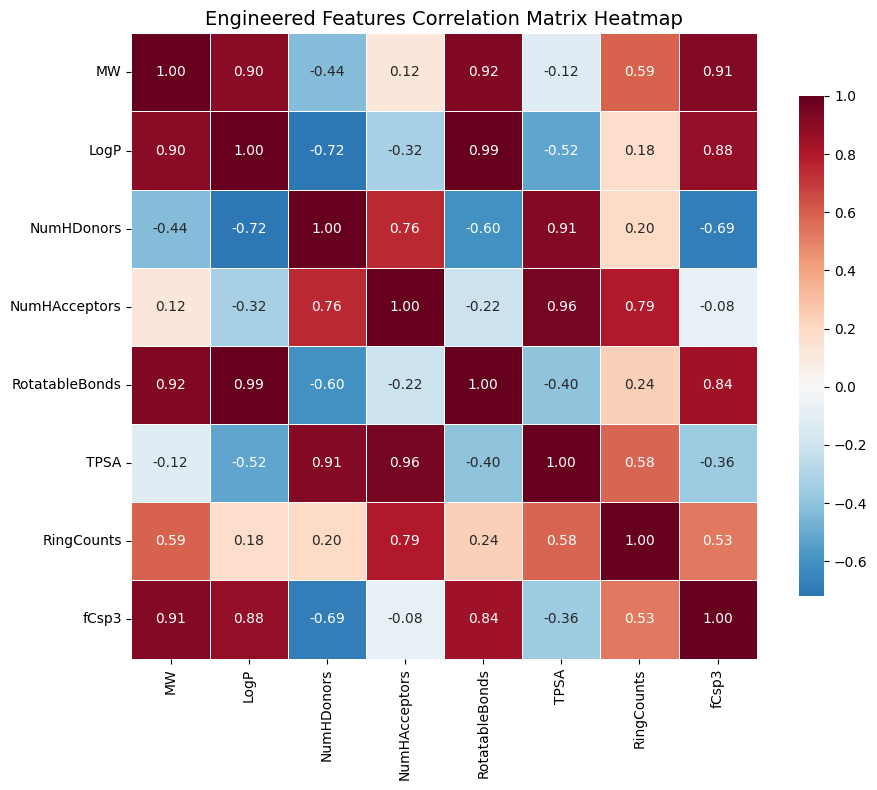

In [2]:
import numpy as np
import pandas as pd
from tabulate import tabulate
import matplotlib.pylab as plt
import seaborn as sns

# All features Engineering will be done in this script, and kept separated from the general preProcessing

# The first obvious feature to add will be the Molecular Weights (From PubChem)
MWs = {"Auraptene": 298.4,
       "Osthole": 244.28,
       "Esculetin": 178.14,
       "GalbanicAcid": 398.5,
       "Umbelliprenin": 366.5};

# The second Important Feature will be LogP (XLogP3 From PubChem)
LogPs = {"Auraptene": 5.3,
         "Osthole": 3.8,
         "Esculetin": 1.2,
         "GalbanicAcid": 5.1,
         "Umbelliprenin": 7.1}

# Number of the Hydrogen bond donors
numHDonors = {"Auraptene": 0,
              "Osthole": 0,
              "Esculetin": 2,
              "GalbanicAcid": 1,
              "Umbelliprenin": 0}

# Number of the Hydrohen bond acceptors
numHAcceptors = {"Auraptene": 3,
                 "Osthole": 3,
                 "Esculetin": 4,
                 "GalbanicAcid": 5,
                 "Umbelliprenin": 3}

# Number of rotatable bonds
rotatableBonds = {"Auraptene": 6,
                  "Osthole": 3,
                  "Esculetin": 0,
                  "GalbanicAcid": 6,
                  "Umbelliprenin": 9}

# Topological Polar Surface Area (From PubChem)
TPSAs = {"Auraptene": 35.5,
         "Osthole": 35.5,
         "Esculetin": 66.8,
         "GalbanicAcid": 72.8,
         "Umbelliprenin": 35.5}

# Ring Counts
ringCounts = {"Auraptene": 2,
              "Osthole": 2,
              "Esculetin": 2,
              "GalbanicAcid": 3,
              "Umbelliprenin": 2}

# FractionCsp3: The fraction of carbon atoms that are sp3 hybridized.
fCsp3s = {"Auraptene": 0.32,
          "Osthole": 0.27,
          "Esculetin": 0,
          "GalbanicAcid": 0.5,
          "Umbelliprenin": 0.38}


# Read the data
data = pd.read_csv("Data/Final_Data.csv")

# Add the new features
data["MW"] = data["Coumarin"].map(MWs)
data["LogP"] = data["Coumarin"].map(LogPs)
data["NumHDonors"] = data["Coumarin"].map(numHDonors)
data["NumHAcceptors"] = data["Coumarin"].map(numHAcceptors)
data["RotatableBonds"] = data["Coumarin"].map(rotatableBonds)
data["TPSA"] = data["Coumarin"].map(TPSAs)
data["RingCounts"] = data["Coumarin"].map(ringCounts)
data["fCsp3"] = data["Coumarin"].map(fCsp3s)

# Take a look at the new data structure and columns
print("Head of the data after new features:")
print(tabulate(data.head(), headers='keys', tablefmt='grid'))

# Check out the correlation matrix of the new features
cols = ["MW", "LogP", "NumHDonors", "NumHAcceptors", "RotatableBonds", "TPSA", "RingCounts", "fCsp3"]
corr_matrix = data[cols].corr()
print("\nCorrelation Matrix of the newly engineered features:")
print(tabulate(corr_matrix, headers='keys', tablefmt='grid'))

# Create heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(corr_matrix, 
            annot=True,                # Show values
            cmap='RdBu_r',             # Color scheme
            center=0,                  # Center colormap at 0
            fmt='.2f',                 # 2 decimal places
            square=True,               # Square cells
            linewidths=0.5,            # Grid lines
            cbar_kws={"shrink": 0.8})  # Colorbar size

plt.title('Engineered Features Correlation Matrix Heatmap', fontsize=14)
plt.tight_layout()

plt.show()

# Given the results of the Correlation matrix I have decided that adding cross features could be
# of negative effect to the overall extrapolation process.

---
## XGBoostRegressor



In [3]:
import numpy as np
np.random.seed(42)  # All random processes are seeded with 42 for reproducibility

import pandas as pd
import os
import json
import joblib

from xgboost import XGBRegressor

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    train_test_split,
    KFold,
    GroupKFold,
    RandomizedSearchCV
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score
)

from tabulate import tabulate

# Load the data
data = pd.read_csv("Data/Engineered_Data.csv")

# Set constants here
RANDOM_STATE = 42
RESULTS_DIR = "Results/Regression/"
MODELS_DIR = RESULTS_DIR + "Models/"
EVALUATIONS_DIR = RESULTS_DIR + "Evaluations/"
PARAMETERS_DIR = RESULTS_DIR + "BestParameters/"
N_ITER = 3000 # Number of iterations for the random search

# Make the required directories if they do not exist
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(EVALUATIONS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(PARAMETERS_DIR, exist_ok=True)

# Take a look at the head of the data
print("=" * 70)
print("STARTING XGBOOST REGRESSION SCRIPT")
print("=" * 70)

print()
print("Head of the raw data: (Shuffled to see more variance in the data)\n")
print(tabulate(data.sample(frac=1).head(), headers='keys', tablefmt="rounded_grid"))
print()

# Set X and y
print()
print("=" * 70)
print("DEFINING X AND y")
print("=" * 70)
print()
X = data.drop(columns=["Viability", "Author", "Coumarin"], inplace=False)
y = data['Viability']

print("X features:")
print(tabulate(pd.DataFrame(X.columns), tablefmt="rounded_grid"), end="\n\n")
print("The y vector has been set to the `Viability` feature")

# Define the categorical and numerical features
categorical_features = ["Cancer", "CellLine"]
numerical_features = X.columns.drop(["Cancer", "CellLine"]).tolist()

# Define Groups for evaluation and parameter searching
data["GroupID"] = (
    data["Author"].astype(str) + "_" +
    data["Coumarin"].astype(str) + "_" +
    data["CellLine"].astype(str) + "_" +
    data["Time"].astype(str)
)
print()
print("=" * 70)
print("Defining Grouping Strategies")
print("=" * 70)
print()

print("1. Grouping using the Author, Coumarin, CellLinem and Time Features")
print("Number of uniquely identified groups:", data["GroupID"].nunique())
print()

print("2. Grouping using the Coumarin feature")
print("Number Groups using only Coumarins:", data["Coumarin"].nunique())
print()

print("3. The final strategy will be the usual Kfold using 5 folds")

# Prepare the preprocessor
preprocessor = ColumnTransformer(
    transformers= [(
        "cat",
        OneHotEncoder(sparse_output=False, handle_unknown="ignore"),
        categorical_features
    ),
    (
        "num",
        "passthrough",
        numerical_features
    )]
)

# Initialize the base model object
model = XGBRegressor(
    objective="reg:squarederror",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

# Define pipeline
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model)
])

# Define the search grid of the model for fine tuning the hyper parameters (Using randomSearch)
param_distributions = {
    "model__n_estimators": [
        100, 150, 200, 300, 400, 500,
        600, 800, 1000
    ],

    "model__max_depth": [
        2, 3, 4, 5, 6, 7, 8
    ],

    "model__learning_rate": [
        0.005, 0.01, 0.02, 0.03,
        0.05, 0.075, 0.1, 0.15, 0.2
    ],

    "model__subsample": [
        0.5, 0.6, 0.7, 0.8,
        0.9, 1.0
    ],

    "model__colsample_bytree": [
        0.5, 0.6, 0.7, 0.8,
        0.9, 1.0
    ],

    "model__min_child_weight": [
        1, 2, 3, 5, 7, 10
    ],

    "model__gamma": [
        0, 0.01, 0.05, 0.1,
        0.2, 0.5, 1.0
    ],

    "model__reg_alpha": [
        0, 0.001, 0.01, 0.1, 1.0
    ],

    "model__reg_lambda": [
        0.1, 0.5, 1, 2, 5, 10
    ]
}

# Evaluation methods:
eval_methods = {
    "Kfold" : {
        "splitter" : KFold(
            n_splits=5,
            shuffle=True,
            random_state=RANDOM_STATE
        ),
        "groups" : None
    },

    "GroupID" : {
        "splitter" : GroupKFold(
            n_splits=5
        ),
        "groups" : data["GroupID"]
    },

    "Coumarin" : {
        "splitter" : GroupKFold(
            n_splits=data["Coumarin"].nunique()
        ),
        "groups" : data["Coumarin"]
    }
}

# Next up we'll define some helpers so that reproducubility under different conditions is simplified

#===================================================================================================
# Helper function to get the results of evaluation
def calculate_metrics(y_true, y_pred):
    """
    Returns a Dict containing the following metrics as keys:
    - "MAE"
    - "RMSE"
    - "MedAE"
    - "R2"

    :param y_true: The true y vector.
    :param y_pred: The y that has been predicted by a model.
    """
    return {
        "MAE" : mean_absolute_error(y_true, y_pred),
        "RMSE" : np.sqrt(mean_squared_error(y_true, y_pred)),
        "MedAE" : median_absolute_error(y_true, y_pred),
        "R2" : r2_score(y_true, y_pred)
    };

# A helper function to return a freash pipeline if needed
def create_model():

    return Pipeline([
        (
            "preprocessor",
            ColumnTransformer(
                transformers=[
                    (
                        "cat",
                        OneHotEncoder(
                            sparse_output=False,
                            handle_unknown="ignore"
                        ),
                        categorical_features
                    ),
                    (
                        "num",
                        "passthrough",
                        numerical_features
                    )
                ]
            )
        ),
        (
            "model",
            XGBRegressor(
                objective="reg:squarederror",
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        )
    ]);

# Helper function that will return a pipeline that has been fitted to the given params
def create_model_with_params(best_params):

    model_pipeline = create_model()

    model_pipeline.set_params(
        **best_params
    )

    return model_pipeline;

# A Function that will allow us to perform the search under different conditions if needed
def search_best_parameters(method_name, splitter, groups):
    """
    Performs RandomizedSearchCV if the best-parameter JSON
    does not already exist.

    If the JSON exists, the search is skipped and the
    previously determined parameters are loaded instead.
    """

    parameter_path = (
        PARAMETERS_DIR +
        f"XGBoost_{method_name}.json"
    )

    print()
    print("=" * 70)
    print(f"Starting hyperparameter search: {method_name}")
    print("=" * 70)
    print()

    # --------------------------------------------------------
    # Check whether the search has already been performed
    # --------------------------------------------------------

    if os.path.exists(parameter_path):

        print(f"[{method_name}] Best parameters already exist.")
        print("Skipping hyperparameter search.")

        with open(
            parameter_path,
            "r"
        ) as file:

            best_params = json.load(file)

        return best_params


    # --------------------------------------------------------
    # Perform the search if the json does not exist
    # --------------------------------------------------------

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions,
        n_iter=N_ITER,
        scoring="r2",
        cv=splitter,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=False,
        verbose=1
    )

    if groups is None:

        search.fit(
            X,
            y
        )

    else:

        search.fit(
            X,
            y,
            groups=groups
        )

    # --------------------------------------------------------
    # Retrieve best parameters post searching
    # --------------------------------------------------------

    best_params = search.best_params_

    print()
    print(
        f"Best CV R2 for {method_name}: "
        f"{search.best_score_:.6f}"
    )

    print()
    print("Best parameters:")

    for parameter, value in best_params.items():
        print(
            f"  {parameter}: {value}"
        )

    # --------------------------------------------------------
    # Save parameters
    # --------------------------------------------------------

    with open(
        parameter_path,
        "w"
    ) as file:

        json.dump(
            best_params,
            file,
            indent=4
        )

    print()
    print(
        f"Best parameters saved to: "
        f"{parameter_path}"
    )

    return best_params;

# A function that will allow us to find metrics other than the R2 used in the search
def evaluate_model(
    method_name,
    splitter,
    groups,
    best_params
):
    """
    Evaluates a model with fixed hyperparameters using the
    same CV strategy that was used during hyperparameter
    searching.

    A fresh model is fitted for every fold.

    Returns:
        - fold-level results
        - mean metrics
        - standard deviations
    """

    print()
    print("=" * 70)
    print(
        f"Evaluating best model: using {method_name} splitting method"
    )
    print("=" * 70)
    print()

    fold_results = []

    # --------------------------------------------------------
    # Generate the same CV splits used during the search
    # --------------------------------------------------------

    if groups is None:

        split_iterator = splitter.split(
            X,
            y
        )

    else:

        split_iterator = splitter.split(
            X,
            y,
            groups=groups
        )

    # --------------------------------------------------------
    # Evaluate every fold
    # --------------------------------------------------------

    for fold_number, (train_idx, test_idx) in enumerate(
        split_iterator,
        start=1
    ):

        print(
            f"Evaluating fold {fold_number}..."
        )

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        # Fresh model for this fold
        fold_model = create_model_with_params(
            best_params
        )

        # Fit ONLY on the training portion
        fold_model.fit(
            X_train,
            y_train
        )

        # Predict the held-out portion
        y_pred = fold_model.predict(
            X_test
        )

        # Calculate all metrics
        metrics = calculate_metrics(
            y_test,
            y_pred
        )

        fold_results.append({
            "Method": method_name,
            "Fold": fold_number,
            **metrics
        })

        print(
            f"  R2:    {metrics['R2']:.6f}"
        )
        print(
            f"  MAE:   {metrics['MAE']:.6f}"
        )
        print(
            f"  RMSE:  {metrics['RMSE']:.6f}"
        )
        print(
            f"  MedAE: {metrics['MedAE']:.6f}"
        )
        print()

    # --------------------------------------------------------
    # Convert fold results to DataFrame
    # --------------------------------------------------------

    fold_results_df = pd.DataFrame(
        fold_results
    )

    # --------------------------------------------------------
    # Calculate mean and standard deviation
    # --------------------------------------------------------

    metrics = [
        "MAE",
        "RMSE",
        "MedAE",
        "R2"
    ]

    summary = {}

    for metric in metrics:

        summary[
            f"{metric}_Mean"
        ] = fold_results_df[metric].mean()

        summary[
            f"{metric}_Std"
        ] = fold_results_df[metric].std()

    return fold_results_df, summary;
#===================================================================================================

# We are done with the helper functions now we can start the process of searching and evaluating

all_fold_results = []
all_summary_results = []

for method_name, method in eval_methods.items():
    
    # Set the splitter and the groups to be used in the search and evaluation
    splitter = method["splitter"]
    groups = method["groups"]

    # Get the best_params from the model
    best_params = search_best_parameters(
        method_name=method_name,
        splitter=splitter,
        groups=groups
    )

    # Get the results of the evaluation
    fold_results_df, summary = evaluate_model(
        method_name=method_name,
        splitter=splitter,
        groups=groups,
        best_params=best_params
    )

    # Store fold level results
    all_fold_results.append(fold_results_df)

    # Store our summary
    all_summary_results.append({
        "Method" : method_name,
        **summary # unpack the summary dict
    });


# Lets combine the results to one df
all_fold_results_df = pd.concat(all_fold_results, ignore_index=True)
summary_df = pd.DataFrame(all_summary_results)

# Log the results in the terminal
print()
print("=" * 70)
print("FOLD-LEVEL EVALUATION RESULTS")
print("=" * 70)
print()

print(tabulate(all_fold_results_df, headers="keys", tablefmt="rounded_grid", showindex=False, floatfmt=".6f"))

print()
print("=" * 70)
print("EVALUATION SUMMARY")
print("=" * 70)
print()

print(tabulate(summary_df, headers="keys", tablefmt="rounded_grid", showindex=False, floatfmt=".6f"))

# Now we can finally save the results as a csv file
all_fold_results_df.to_csv(
    EVALUATIONS_DIR +
    "XGBoost_FoldResults.csv",
    index=False
)

summary_df.to_csv(
    EVALUATIONS_DIR +
    "XGBoost_EvaluationSummary.csv",
    index=False
)

print()
print("Evaluation results saved.")

# Now that we are done with searching and evaluating, We can finally train the models on the whole dataset
print()
print("=" * 70)
print("TRAINING FINAL MODELS")
print("=" * 70)
print()


for method_name, method in eval_methods.items():

    parameter_path = (
        PARAMETERS_DIR +
        f"XGBoost_{method_name}.json"
    )

    model_path = (
        MODELS_DIR +
        f"XGBoost_{method_name}.joblib"
    )

    # --------------------------------------------------------
    # Load best parameters
    # --------------------------------------------------------

    with open(
        parameter_path,
        "r"
    ) as file:

        best_params = json.load(file)

    # --------------------------------------------------------
    # Create fresh model
    # --------------------------------------------------------

    final_model = create_model_with_params(
        best_params
    )

    # --------------------------------------------------------
    # Train on ALL available data
    # --------------------------------------------------------

    final_model.fit(
        X,
        y
    )

    # --------------------------------------------------------
    # Save final model
    # --------------------------------------------------------

    joblib.dump(
        final_model,
        model_path
    )

    print(f"{method_name} final model saved to:")
    print(f"  {model_path}")

print()
print("=" * 70)
print("TESTING THE MODEL ON SCOPOLETIN SAMPLES")
print("=" * 70)
print()

scopoletin_samples = [{
    "Cancer" : [],
    "CellLine" : [],
    "Dose" : [],
    "Time" : [],
    "Viability" : []
    },
]

scopoletin_structural_features = {
    "MW" : 192.17, # From PubChem
    "LogP" : 1.5, # From PubChem
    "NumHDonors" : 1, # From PubChem
    "NumHAcceptors" : 4, # From PubChem
    "RotatableBonds" : 1, # From PubChem
    "TPSA" : 55.8, # From PubChem
    "RingCounts" : 2, # From PubChem Figure
    "fCsp3" : 0.10 # From SwissADME
}



print()
print("=" * 70)
print("TESTING THE MODEL ON IMPERATORIN SAMPLES")
print("=" * 70)
print()

imperatorin_samples = [{
    "Cancer" : [],
    "CellLine" : [],
    "Dose" : [],
    "Time" : [],
    "Viability" : []
    },
]

scopoletin_structural_features = {
    "MW" : 270.28, # From PubChem
    "LogP" : 3.4, # From PubChem
    "NumHDonors" : 0, # From PubChem
    "NumHAcceptors" : 4, # From PubChem
    "RotatableBonds" : 3, # From PubChem
    "TPSA" : 48.7, # From PubChem
    "RingCounts" : 3, # From PubChem Figure
    "fCsp3" : 0.19 # From SwissADME
}


print()
print("=" * 70)
print("FINISHED SCRIPT SUCCESSFULLY!!!")
print("=" * 70)
print()

STARTING XGBOOST REGRESSION SCRIPT

Head of the raw data: (Shuffled to see more variance in the data)

╭──────┬───────────────────┬───────────────────┬────────────┬──────────────┬────────┬────────┬─────────────┬────────┬────────┬──────────────┬─────────────────┬──────────────────┬────────┬──────────────┬─────────╮
│      │ Author            │ Cancer            │ CellLine   │ Coumarin     │   Dose │   Time │   Viability │     MW │   LogP │   NumHDonors │   NumHAcceptors │   RotatableBonds │   TPSA │   RingCounts │   fCsp3 │
├──────┼───────────────────┼───────────────────┼────────────┼──────────────┼────────┼────────┼─────────────┼────────┼────────┼──────────────┼─────────────────┼──────────────────┼────────┼──────────────┼─────────┤
│  618 │ Goudarzi et al.   │ leukemia:lymphoma │ MT-2       │ GalbanicAcid │     10 │     72 │       92.2  │ 398.5  │    5.1 │            1 │               5 │                6 │   72.8 │            3 │    0.5  │
├──────┼───────────────────┼─────────────────

## XGBoost Classification script
In the following script we use the xgboost classification model and the viability feature has been transformed to two classes under the following condition:
> if |Viability - 50| ≤ 5 then set Viability to 1, set Viability to 0 otherwise

In [4]:
import numpy as np
np.random.seed(42)  # All random processes are seeded with 42 for reproducibility

import pandas as pd
import os
import json
import joblib

from xgboost import XGBClassifier

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    train_test_split,
    KFold,
    GroupKFold,
    RandomizedSearchCV
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score
)

from tabulate import tabulate

# Load the data
data = pd.read_csv("Data/Engineered_Data.csv")

print("=" * 70)
print("STARTING XGBOOST REGRESSION SCRIPT")
print("=" * 70)

# Make the Viability feature categorical(1 if |Viability - 50| ≤ 5 and 0 otherwise)
print()
print("=" * 70)
print("TRANSFORMING VIABILITY FEATURE FOR CLASSIFICATION")
print("=" * 70)
print()

data['Viability'] = data['Viability'].apply(lambda x: 1 if abs(x - 50) <= 5 else 0)
print("Viability has been transformed by the following citeria:")
print("if |Viability - 50| ≤ 5 then set Viability to 1, set Viability to 0 otherwise")
print()

# The distribution of the classes
print("The distribution of the new clasees of Viability:")
print(tabulate(pd.DataFrame(data["Viability"].value_counts()), headers="keys", tablefmt="rounded_grid"))

# Set constants here
RANDOM_STATE = 42
RESULTS_DIR = "Results/Classification/"
MODELS_DIR = RESULTS_DIR + "Models/"
EVALUATIONS_DIR = RESULTS_DIR + "Evaluations/"
PARAMETERS_DIR = RESULTS_DIR + "BestParameters/"
N_ITER = 3000 # Number of iterations for the random search

# Make the required directories if they do not exist
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(EVALUATIONS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(PARAMETERS_DIR, exist_ok=True)

# Take a look at the head of the data
print()
print("Head of the raw data: (Shuffled to see more variance in the data)\n")
print(tabulate(data.sample(frac=1).head(), headers='keys', tablefmt="rounded_grid"))
print()

STARTING XGBOOST REGRESSION SCRIPT

TRANSFORMING VIABILITY FEATURE FOR CLASSIFICATION

Viability has been transformed by the following citeria:
if |Viability - 50| ≤ 5 then set Viability to 1, set Viability to 0 otherwise

The distribution of the new clasees of Viability:
╭─────────────┬─────────╮
│   Viability │   count │
├─────────────┼─────────┤
│           0 │    1531 │
├─────────────┼─────────┤
│           1 │     166 │
╰─────────────┴─────────╯

Head of the raw data: (Shuffled to see more variance in the data)

╭──────┬───────────────────┬───────────────────┬────────────┬──────────────┬────────┬────────┬─────────────┬────────┬────────┬──────────────┬─────────────────┬──────────────────┬────────┬──────────────┬─────────╮
│      │ Author            │ Cancer            │ CellLine   │ Coumarin     │   Dose │   Time │   Viability │     MW │   LogP │   NumHDonors │   NumHAcceptors │   RotatableBonds │   TPSA │   RingCounts │   fCsp3 │
├──────┼───────────────────┼───────────────────┼───